In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.special import logsumexp

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset = fetch_ucirepo(id=292)

df = dataset.data.features.copy()

features = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicassen'
]

df = df[features]

print(df.head())

print("\nDataset Shape:", df.shape)

   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844
3  13265  1196     4221    6404               507        1788
4  22615  5410     7198    3915              1777        5185

Dataset Shape: (440, 6)


In [3]:
print(df.info())

print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Fresh             440 non-null    int64
 1   Milk              440 non-null    int64
 2   Grocery           440 non-null    int64
 3   Frozen            440 non-null    int64
 4   Detergents_Paper  440 non-null    int64
 5   Delicassen        440 non-null    int64
dtypes: int64(6)
memory usage: 20.8 KB
None
               Fresh          Milk       Grocery        Frozen  \
count     440.000000    440.000000    440.000000    440.000000   
mean    12000.297727   5796.265909   7951.277273   3071.931818   
std     12647.328865   7380.377175   9503.162829   4854.673333   
min         3.000000     55.000000      3.000000     25.000000   
25%      3127.750000   1533.000000   2153.000000    742.250000   
50%      8504.000000   3627.000000   4755.500000   1526.000000   
75%     16933.750000   7190.250000  10655

<Figure size 1200x700 with 0 Axes>

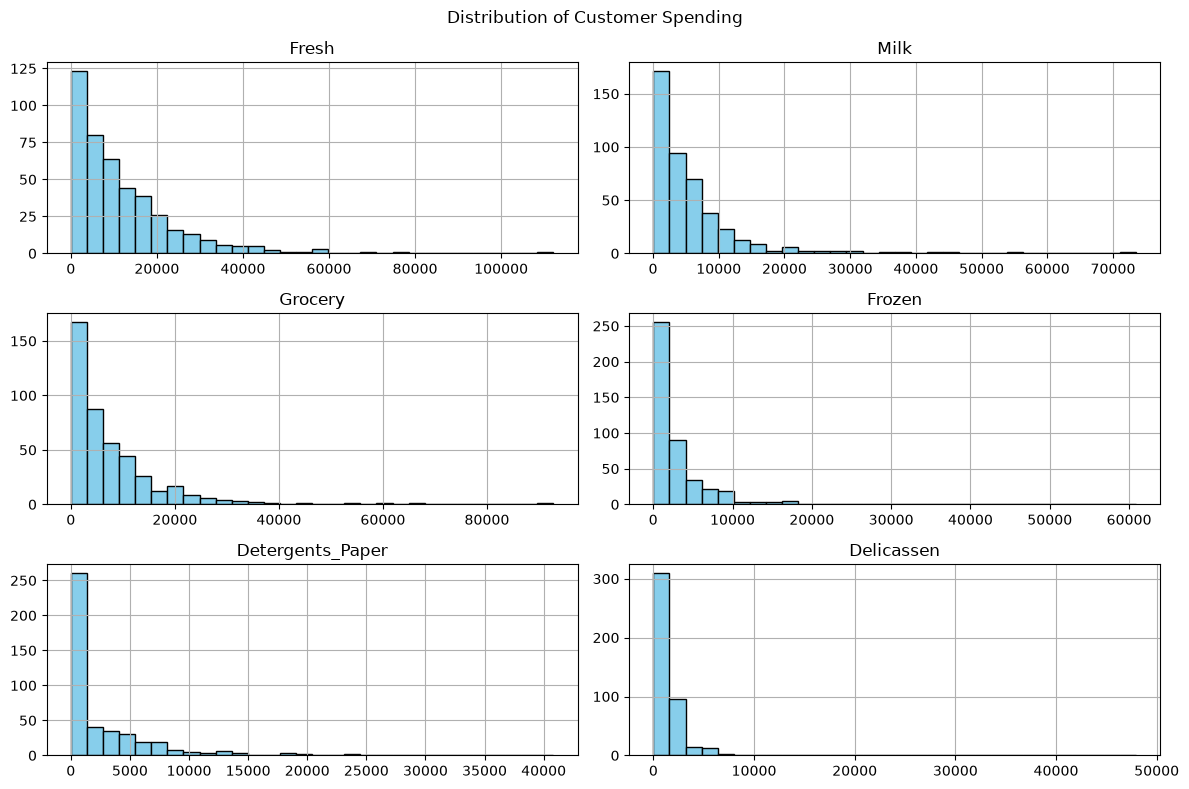

In [4]:
plt.figure(figsize=(12, 7))

df.hist(figsize=(12, 8), bins=30, color='skyblue',
        edgecolor='black')

plt.suptitle("Distribution of Customer Spending")
plt.tight_layout()
plt.show()

In [5]:
X_log = np.log1p(df)

scaler = StandardScaler()

X = scaler.fit_transform(X_log)

print("Processed Data Shape:", X.shape)

print("\nFirst Five Processed Records:")
print(X[:5])

Processed Data Shape: (440, 6)

First Five Processed Records:
[[ 0.4861845   0.97629884  0.44015468 -1.50924981  0.64414327  0.40896595]
 [ 0.08788863  0.99095612  0.65217085  0.13405226  0.76604314  0.62792606]
 [ 0.01635628  0.89115098  0.45468702  0.37689926  0.80440496  1.77683339]
 [ 0.51747725 -0.95797283 -0.08479166  1.14157433 -0.3287115   0.63313326]
 [ 0.8806309   0.43966195  0.39584651  0.75732216  0.40493851  1.4565879 ]]


In [6]:
def initialize_parameters(X, K):

    n, d = X.shape

    # Initialize means using K-Means
    kmeans = KMeans(
        n_clusters=K,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    means = kmeans.cluster_centers_

    # Initialize covariance matrices
    global_cov = np.cov(X, rowvar=False)

    covariances = np.array([
        global_cov + 1e-6 * np.eye(d)
        for _ in range(K)
    ])

    # Initialize equal mixing coefficients
    weights = np.ones(K) / K

    return weights, means, covariances

In [7]:
def gaussian_log_probability(X, mean, covariance):

    n, d = X.shape

    diff = X - mean

    # Calculate determinant
    sign, log_det = np.linalg.slogdet(covariance)

    if sign <= 0:
        raise ValueError("Covariance matrix is not positive definite")

    # Calculate inverse-related quadratic form
    solved = np.linalg.solve(covariance, diff.T)

    quadratic = np.sum(diff.T * solved)

    # Log Gaussian probability
    log_prob = -0.5 * (
        n * d * np.log(2 * np.pi)
        + n * log_det
        + quadratic
    )

    # Individual observation probabilities
    individual = -0.5 * (
        d * np.log(2 * np.pi)
        + log_det
        + np.sum(diff * solved.T, axis=1)
    )

    return individual

In [8]:
def expectation_step(X, weights, means, covariances):

    n = X.shape[0]
    K = len(weights)

    log_prob = np.zeros((n, K))

    for k in range(K):

        log_prob[:, k] = (
            np.log(weights[k]) +
            gaussian_log_probability(
                X,
                means[k],
                covariances[k]
            )
        )

    # Normalize probabilities
    log_likelihood = logsumexp(log_prob, axis=1)

    responsibilities = np.exp(
        log_prob - log_likelihood[:, np.newaxis]
    )

    total_log_likelihood = np.sum(log_likelihood)

    return responsibilities, total_log_likelihood

In [9]:
def maximization_step(X, responsibilities):

    n, d = X.shape
    K = responsibilities.shape[1]

    # Effective number of points in each component
    Nk = responsibilities.sum(axis=0)

    # Update weights
    weights = Nk / n

    # Update means
    means = (responsibilities.T @ X) / Nk[:, None]

    # Update covariance matrices
    covariances = np.zeros((K, d, d))

    for k in range(K):

        diff = X - means[k]

        covariances[k] = (
            (responsibilities[:, k][:, None] * diff).T
            @ diff
        ) / Nk[k]

        # Numerical stability
        covariances[k] += 1e-6 * np.eye(d)

    return weights, means, covariances

In [10]:
def EM_GMM(X, K, max_iter=200, tolerance=1e-5):

    # Initialize parameters
    weights, means, covariances = initialize_parameters(X, K)

    previous_log_likelihood = -np.inf

    history = []

    for iteration in range(max_iter):

        # E-step
        responsibilities, log_likelihood = expectation_step(
            X, weights, means, covariances
        )

        # M-step
        weights, means, covariances = maximization_step(
            X, responsibilities
        )

        history.append(log_likelihood)

        # Check convergence
        if abs(log_likelihood - previous_log_likelihood) < tolerance:

            print("Converged at iteration:", iteration + 1)
            break

        previous_log_likelihood = log_likelihood

    # Final E-step with updated parameters
    responsibilities, log_likelihood = expectation_step(
        X, weights, means, covariances
    )

    # Assign each customer to the most probable cluster
    labels = np.argmax(responsibilities, axis=1)

    return (
        weights,
        means,
        covariances,
        responsibilities,
        labels,
        history
    )

In [11]:
K = 3

weights, means, covariances, responsibilities, labels, history = EM_GMM(
    X,
    K
)

print("\nFinal Mixing Coefficients:")
print(weights)

print("\nFinal Means:")
print(means)

print("\nFinal Cluster Assignments:")
print(labels)

print("\nFinal Log Likelihood:")
print(history[-1])

Converged at iteration: 146

Final Mixing Coefficients:
[0.14952744 0.32380285 0.52666971]

Final Means:
[[-0.76586137 -0.11580398  0.17880083 -0.54897727 -0.33706188 -0.90224915]
 [-0.14773879  0.79936031  0.85049591 -0.3646665   1.01843042  0.31844664]
 [ 0.3082682  -0.45857825 -0.57365864  0.38006213 -0.53044757  0.06037384]]

Final Cluster Assignments:
[1 1 1 2 1 1 1 1 1 1 1 2 1 1 1 2 1 2 1 2 1 2 2 1 1 1 2 2 1 2 2 2 1 2 2 1 2
 1 1 2 2 1 1 0 1 1 1 1 1 1 2 1 1 1 2 1 1 1 2 1 1 1 1 1 2 1 0 1 2 2 2 0 2 2
 2 2 0 1 2 1 2 1 1 2 1 1 0 1 0 2 2 2 1 2 1 0 0 0 0 2 1 1 1 2 2 2 1 1 1 0 2
 1 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 1 0 2 2 2 2 2 2 2 1 0 0 2 2 0 0 2 0 0 2 2
 2 2 2 2 2 2 0 1 1 2 1 1 1 0 2 1 1 1 1 1 2 2 1 1 1 1 0 1 2 0 0 2 2 1 1 0 0
 2 2 0 1 1 0 2 2 0 2 2 2 1 2 2 1 1 2 0 0 1 2 1 1 1 2 1 2 1 1 1 1 2 0 2 2 1
 2 2 2 2 1 2 2 2 2 2 2 0 2 2 2 2 2 2 2 2 2 1 1 1 2 2 2 2 2 1 2 0 2 2 2 2 2
 2 2 2 2 2 1 2 0 2 1 2 2 2 0 2 2 2 2 2 2 1 2 1 2 2 2 0 2 2 2 0 1 2 2 1 2 1
 2 1 1 0 1 1 1 1 1 0 1 2 2 1 2 0 0 2 2 1 

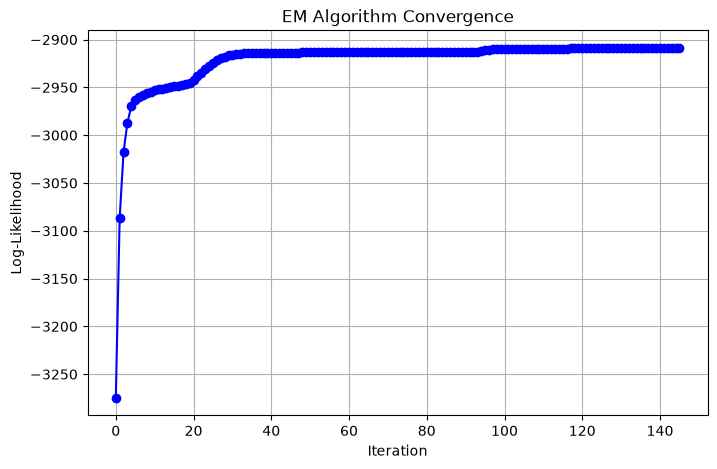

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history, marker='o', color='blue')

plt.title("EM Algorithm Convergence")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")

plt.grid(True)
plt.show()